In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.distributions import Categorical, Normal
from torch.utils.data import Dataset, DataLoader
import numpy as np
import math
import random
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy.stats import norm

device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [3]:
# custom activation function having ELU + 1
class NNeLU(nn.Module):
    def __init__(self, alpha=1.0, epsilon=1e-15):
        super(NNeLU, self).__init__()
        self.eLU = nn.ELU(alpha=alpha)
        self.epsilon = epsilon

    def forward(self, x):
        return self.eLU(x) + 1 + self.epsilon

In [4]:
class Transformer(nn.Module):
    def __init__(self, n_Layers, n_Embd=16, max_seq_length=20, n_Classes=1, dist_embed=1):
        super(Transformer, self).__init__()
        
        self.src_embedding = nn.Linear(in_features=n_Classes, out_features=n_Embd)
        self.tgt_embedding = nn.Linear(in_features=n_Classes, out_features=n_Embd)
        
        self.positional_encoding = nn.Parameter(self.create_positional_encoding(max_seq_length, n_Embd), requires_grad=False)
        
        encoder_layer = nn.TransformerEncoderLayer(n_Embd, nhead=8, activation="gelu", batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(encoder_layer, n_Layers)
        
        decoder_layer = nn.TransformerDecoderLayer(n_Embd, nhead=8, activation="gelu", batch_first=True, norm_first=True)
        self.decoder = nn.TransformerDecoder(decoder_layer, n_Layers)
        
        self.mean_lin = nn.Linear(n_Embd, dist_embed)
        self.var_lin = nn.Linear(n_Embd, dist_embed)
        self.weights_lin = nn.Linear(n_Embd, dist_embed)

        # Activations
        self.softmax = nn.Softmax(dim=-1)
        self.relu = nn.ReLU()
        self.nnelu = NNeLU()
        
        self.register_buffer("tril", torch.tril(torch.ones(max_seq_length, max_seq_length)))

        self.init_biases()
        
    def init_biases(self):
        # Predefined centers - these should be determined based on your application
        centers = torch.tensor([-0.5,-0.25,-0.125,-0.05,0,0.05,0.125,0.25,0.5])  # Example: 3 Gaussian components

        # Initialize biases
        with torch.no_grad():
            self.mean_lin.bias = nn.Parameter(centers)

    @staticmethod
    def create_positional_encoding(max_seq_length, n_Embd):
        pe = torch.zeros(max_seq_length, n_Embd)
        position = torch.arange(0, max_seq_length, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, n_Embd, 2).float() * (-math.log(10000.0) / n_Embd))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        return pe.unsqueeze(0)

    def forward(self, src, tgt):

        embedded_src = self.src_embedding(src) + self.positional_encoding[:, :src.size(1), :]
        embedded_tgt = self.tgt_embedding(tgt) + self.positional_encoding[:, :tgt.size(1), :]
        
        memory = self.encoder(embedded_src)

        outs = self.decoder(embedded_tgt, memory, tgt_mask=self.tril[:tgt.size(1), :tgt.size(1)], tgt_is_causal=True)

        mean = self.mean_lin(outs)
        var = self.nnelu(self.var_lin(outs))
        weights = self.weights_lin(outs)
        
        return mean, var, weights


In [5]:
class ChanduLoss(nn.Module):

    def __init__(self):
        super(ChanduLoss, self).__init__()

    def forward(self, true, mean, var, weights):
        # cumprod = torch.cumprod(true, dim=1)
        m = Normal(loc=mean, scale=torch.sqrt(var))
        log_probs = m.log_prob(true.expand_as(mean))

        # mixture = F.gumbel_softmax(weights, tau=1, dim = -1)
        # log_mix = torch.log(mixture)
        log_mix = F.log_softmax(weights, dim=-1)
        reconstruction_loss = -torch.logsumexp(log_probs + log_mix, dim=-1)

        # KL divergence
        kl = -0.5 * (1 + torch.log(var) - var)

        # Seperation loss
        differences = 0.0
        for i in range(0, mean.size(-1)):
            for j in range(0, mean.size(-1)):
                if i != j:
                    differences += torch.abs(mean[:, :, i] - mean[:, :, j]) 
        seperation_loss = 1 / (differences + 1e-15)

        loss = reconstruction_loss.mean() + kl.mean()# + seperation_loss.mean()*10
        # print("KL: ", kl.mean().item(), " Reconstruction: ", reconstruction_loss.mean().item(), " Seperation: ", seperation_loss.mean().item())

        return loss

In [6]:
ONEOVERSQRT2PI = 1.0 / math.sqrt(2 * math.pi)
LOG2PI = math.log(2 * math.pi)

class MDNLoss(nn.Module):

    def __init__(self):
        super(MDNLoss, self).__init__()

    def gaussian_probability(self, sigma, mu, target, log=False):
        """Returns the probability of `target` given MoG parameters `sigma` and `mu`.

        Arguments:
            sigma (BxGxO): The standard deviation of the Gaussians. B is the batch
                size, G is the number of Gaussians, and O is the number of
                dimensions per Gaussian.
            mu (BxGxO): The means of the Gaussians. B is the batch size, G is the
                number of Gaussians, and O is the number of dimensions per Gaussian.
            target (BxI): A batch of target. B is the batch size and I is the number of
                input dimensions.
        Returns:
            probabilities (BxG): The probability of each point in the probability
                of the distribution in the corresponding sigma/mu index.
        """
        target = target.expand_as(sigma)
        if log:
            ret = ( -torch.log(sigma) - 0.5 * LOG2PI - 0.5 * torch.pow((target - mu) / sigma, 2) )
        else:
            ret = (ONEOVERSQRT2PI / sigma) * torch.exp(
                -0.5 * ((target - mu) / sigma) ** 2
            )
        return ret  # torch.prod(ret, 2)

    def log_prob(self, pi, sigma, mu, y):
        log_component_prob = self.gaussian_probability(sigma, mu, y, log=True)
        log_mix_prob = torch.log(
            nn.functional.gumbel_softmax(pi, tau=1, dim=-1) + 1e-15
        )
        return torch.logsumexp(log_component_prob + log_mix_prob, dim=-1)

    def calculate_loss(self, y, pi, sigma, mu, tag="train"):
        # NLL Loss
        log_prob = self.log_prob(pi, sigma, mu, y)
        loss = torch.mean(-log_prob)

        return loss

    def forward(self, true, mean, var, weights):
        
        loss = self.calculate_loss(true, weights, torch.sqrt(var), mean)
        return loss

In [7]:
class Node:
    def __init__(self, prob_distribution):
        self.prob_distribution = prob_distribution
        self.children = []

    def add_child(self, child_distribution):
        child_node = Node(child_distribution)
        self.children.append(child_node)

        return child_node
    
    def print_tree(self, level=0):
        ret = "\t"*level+repr(self.prob_distribution)+"\n"
        for child in self.children:
            ret += child.print_tree(level+1)
        return ret

class ProbabilityTree:
    def __init__(self, discrete_values, depth=4, seed=None):

        initial_state_cpu = None
        if seed is not None:
            initial_state_cpu = torch.get_rng_state()
            torch.manual_seed(seed)

        self.distribution_len = len(discrete_values)

        root_distribution = self.create_random_distribution()
        self.root = Node(root_distribution)
        self.depth = depth
        self.discrete_values = discrete_values

        self.construct_tree(root=self.root, depth=self.depth)

        if initial_state_cpu is not None:
            torch.set_rng_state(initial_state_cpu)

    def create_random_distribution(self):
        distribution = torch.rand(self.distribution_len)*30
        distribution = F.softmax(distribution, dim=0)
        return distribution

    def plot_distribution(self, distribution):
        plt.figure()
        plt.plot(self.discrete_values, distribution)
        plt.show()

    def construct_tree(self, root=None, depth=4):
        if depth == 0:
            return
        if root is None:
            self.depth = depth
            root = self.root
        
        for _ in range(self.distribution_len):
            child_distribution = self.create_random_distribution()
            child_node = root.add_child(child_distribution)
            self.construct_tree(root=child_node, depth=depth-1)

    def sample_from_tree(self):
        samples = []
        root = self.root
        for _ in range(self.depth):
            sample = torch.distributions.Categorical(root.prob_distribution).sample()
            samples.append(self.discrete_values[sample]+torch.randn(1)*0.03)
            root = root.children[sample]
        return torch.cat([torch.zeros(1), torch.Tensor(samples)])

    def __str__(self):
        return self.root.print_tree()


In [8]:
class ProbabilisticDataset:

    def __init__(self, tree, num_samples=1000, device='cpu'):
        self.tree = tree
        self.num_samples = num_samples
        self.encoder_input = torch.tensor([0.05,0.125,0.37,-0.2,-0.17 ]).to(device)
        self.discrete_values = tree.discrete_values.to(device)

        self.samples = []
        self.device = device

        for _ in range(num_samples):
            self.samples.append(self.tree.sample_from_tree().to(device))

    def one_hot_encode(self, data):
        # Find the indices of the closest discrete values
        indices = torch.argmin(abs(self.discrete_values.unsqueeze(1) - data), dim=0)
        # Create one-hot encoded vectors
        one_hot = torch.nn.functional.one_hot(indices, num_classes=len(self.discrete_values)).float()
        return one_hot

    def __len__(self):
        return self.num_samples
    
    def __getitem__(self, idx):
        return  torch.cumprod(self.encoder_input+1, dim=0)-1, torch.cumprod(self.samples[idx]+1, dim=0)-1

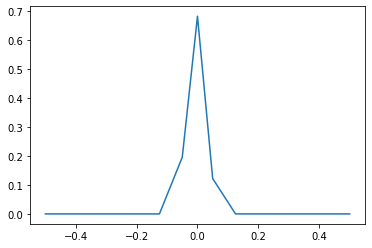

In [9]:
# values = torch.tensor([i for i in range(-20, 21)])/10

tree = ProbabilityTree(torch.tensor([-0.5,-0.25,-0.125,-0.05,0,0.05,0.125,0.25,0.5]), depth=4, seed=42)
tree.plot_distribution(tree.create_random_distribution())
dataset = ProbabilisticDataset(tree, num_samples=999, device=device)

In [ ]:

encoder_input = torch.tensor([0.05,0.125,0.37,-0.2,-0.17 ])     # Shape: [seq_len, 1, feature_size]
target_1 = torch.tensor([0, 0.05,0.125,0.37,0.5,0.67 ])         # Shape: [tgt_seq_len_1, 1, feature_size]
# target_2 = torch.tensor([0, 0.05,0.125,0.37,0.5,0.67 ])       # Shape: [tgt_seq_len_1, 1, feature_size]
target_2 = torch.tensor([0, -0.05,-0.125,-0.37,-0.5,-0.67 ])    # Shape: [tgt_seq_len_2, 1, feature_size]
target_3 = torch.tensor([0, 0.05,0.125,0.37,-0.5,-0.0125 ])     # Shape: [tgt_seq_len_2, 1, feature_size]
target_4 = torch.tensor([0, -0.05,-0.125,-0.37,0.5,0.0125 ])    # Shape: [tgt_seq_len_2, 1, feature_size]
# target_1 = torch.tensor([0, -0.05,-0.125,-0.37,-0.5,-0.67 ])  # Shape: [tgt_seq_len_2, 1, feature_size]

class SampleDataset(Dataset):

    def __init__(self, x, ys, device='cpu'):
        self.discrete_values = torch.tensor([-0.5,-0.25,-0.125,-0.05,0,0.05,0.125,0.25,0.5]).to(device)
        self.x = x.to(device)
        self.ys = ys
        self.device = device

    def __len__(self):
        return len(self.ys)

    def __getitem__(self, idx):
        return self.x, self.ys[idx].to(self.device)

    def one_hot_encode(self, data):
        # Find the indices of the closest discrete values
        indices = torch.argmin(abs(self.discrete_values.unsqueeze(1) - data), dim=0)
        # Create one-hot encoded vectors
        one_hot = torch.nn.functional.one_hot(indices, num_classes=len(self.discrete_values)).float()
        return one_hot

dataset = SampleDataset(encoder_input, [target_1, target_2, target_3, target_4], device=device)


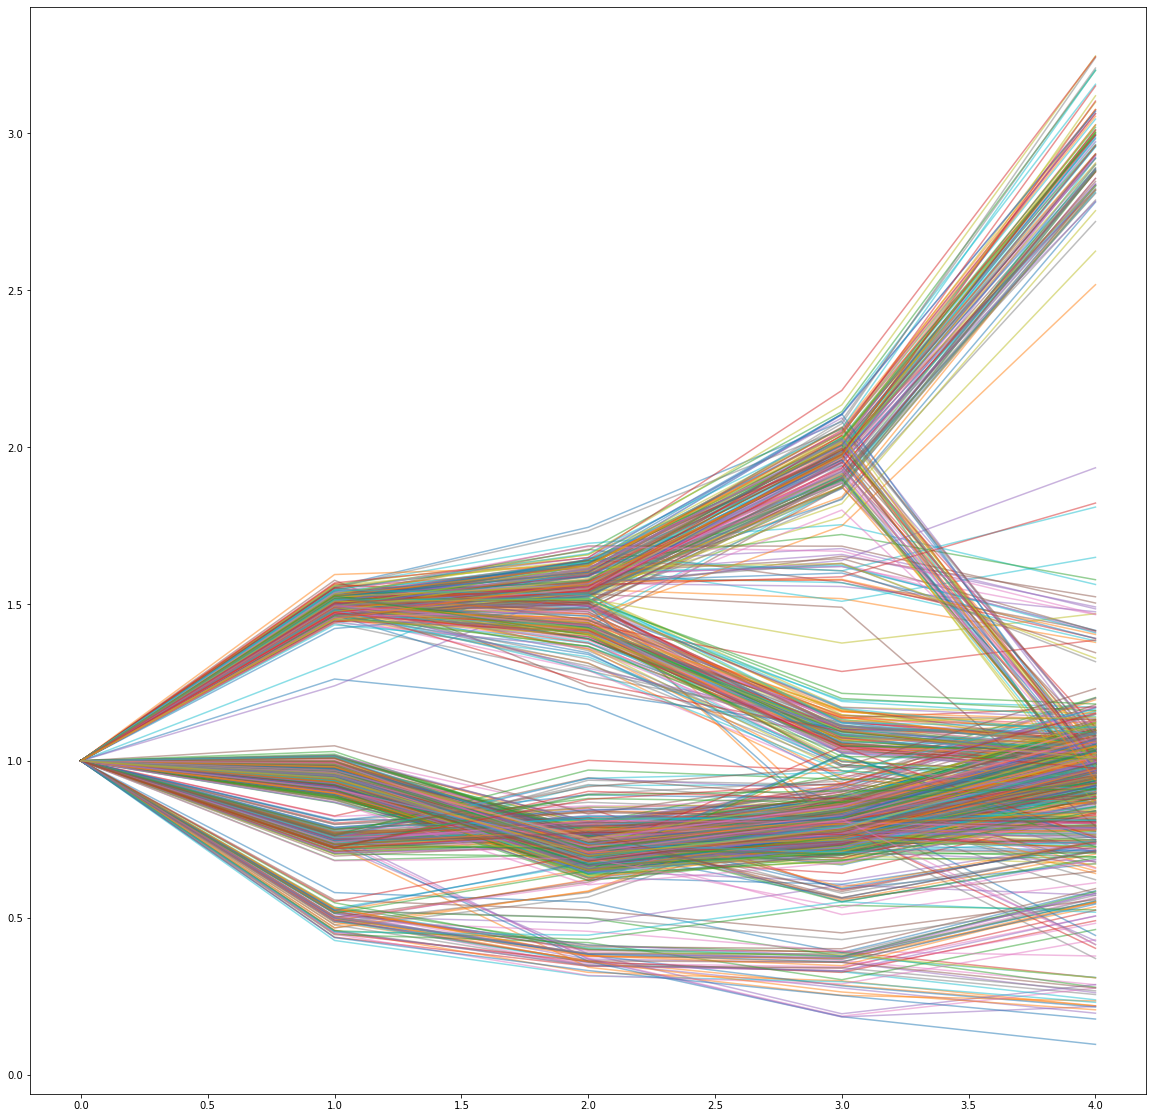

In [10]:
fig = plt.figure(figsize=(20,20))
for i in range(len(dataset)):
    sample = dataset[i][1][1:]
    sample = torch.cat([torch.zeros(1, device=device), sample])+1
    # cumprod = torch.cumprod(sample+1, dim=0).cpu().numpy()

    plt.plot(sample.cpu().numpy(), alpha=0.5)
batch_size = 333
dl = DataLoader(dataset, batch_size=batch_size, shuffle=True)
plt.show()

In [11]:
def calculate_probability(k, epoch):
    v = k / (k + torch.exp(torch.tensor(epoch / k)))
    return v

def flip(p):
    return random.random() < p

def flip_from_probability(p, batch_size, num_features):
    # Generate random numbers from a uniform distribution [0, 1]
    random_numbers = torch.rand(batch_size)
    # Create a boolean tensor where elements are True if the random number is less than p
    boolean_tensor = random_numbers < p

    boolean_tensor = boolean_tensor.unsqueeze(1).expand(-1, num_features)
    return boolean_tensor
    

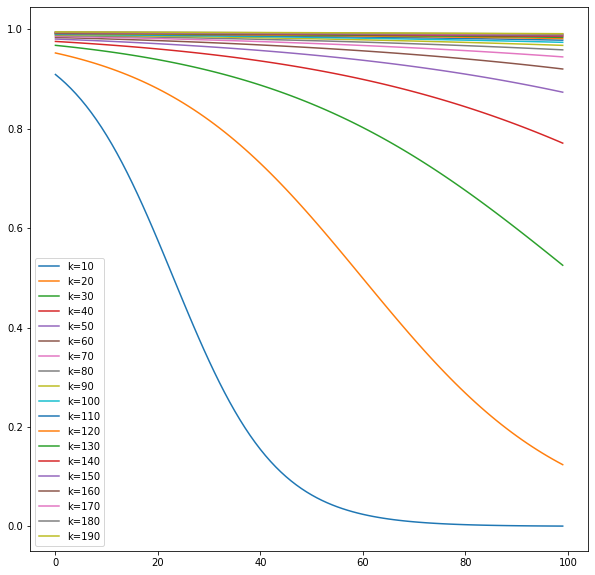

In [12]:
# using matplotlib plot k values from 0.1 -10
plt.figure(figsize=(10,10))
for k in range(10, 200, 10):
    x = []
    y = []
    for epoch in range(100):
        p = calculate_probability(k, epoch)

        x.append(epoch)
        y.append(p)
    plt.plot(x, y, label=f"k={k}")
plt.legend()

In [13]:
n_embedd = 32 
model = Transformer(n_Layers=3, n_Embd=n_embedd, max_seq_length=10, dist_embed=9).to(device)
best_model = Transformer(n_Layers=3, n_Embd=n_embedd, max_seq_length=10, dist_embed=9).to(device)

best_model.load_state_dict(model.state_dict())

# Loss function and optimizer
# criterion = ChanduLoss().to(device)
criterion = MDNLoss().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-5, weight_decay=1e-5)
lr_scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.9)

epochs = 2000
k = 100
val_loss = float('inf')
tau = 1
pbar = tqdm(range(epochs))

for epoch in pbar:
    
    # Training Loop
    model.train()
    p = calculate_probability(k, epoch)
    for batch, target in dl:

        optimizer.zero_grad()
        tgt = target[:,0].unsqueeze(1)

        for i in range(0,target.shape[1]-1):

            mean, var, weight = model(batch.unsqueeze(-1), tgt.unsqueeze(-1))  # Ignoring the last token for target

            if flip(p):
                predicted = torch.cat([tgt, target[:,i+1].unsqueeze(1)], dim=1)
            else:
                gumbel_distribution = F.gumbel_softmax(weight[:, -1], tau=tau, hard=False)
                first_distribution = torch.distributions.Categorical(probs=gumbel_distribution)
                first_sample = first_distribution.sample()
                batch_indices = torch.arange(first_sample.size(0))

                second_distribution = torch.distributions.Normal(mean[:, -1][batch_indices, first_sample], 
                                                       torch.sqrt(var[:, -1][batch_indices, first_sample]))
                second_sample = second_distribution.sample()
                predicted = torch.cat([tgt, second_sample.unsqueeze(1)], dim=1)

            tgt = predicted

        loss = criterion(target[:,1:].unsqueeze(-1), mean, var, weight)

        loss.backward()
        optimizer.step()

    # validation loop
    model.eval()
    with torch.no_grad():
        total_loss = 0
        for batch, target in dl:

            tgt = target[:,0].unsqueeze(1)

            for i in range(0,target.shape[1]-1):

                mean, var, weight = model(batch.unsqueeze(-1), tgt.unsqueeze(-1))  # Ignoring the last token for target

                gumbel_distribution = F.gumbel_softmax(weight[:, -1], tau=tau, hard=False)
                first_distribution = torch.distributions.Categorical(probs=gumbel_distribution)
                first_sample = first_distribution.sample()
                batch_indices = torch.arange(first_sample.size(0))

                second_distribution = torch.distributions.Normal(mean[:, -1][batch_indices, first_sample], 
                                                    torch.sqrt(var[:, -1][batch_indices, first_sample]))
                second_sample = second_distribution.sample()
                predicted = torch.cat([tgt, second_sample.unsqueeze(1)], dim=1)

                tgt = predicted

            loss = criterion(target[:,1:].unsqueeze(-1), mean, var, weight)

            total_loss += loss.sum().item()

        total_loss = total_loss / len(dl)
        if total_loss < val_loss:
            val_loss = total_loss
            best_model.load_state_dict(model.state_dict())

    # lr_scheduler.step()
    pbar.set_description(desc=f"Epoch: {epoch}, Loss: {total_loss}, Best Loss: {val_loss}, p: {p}")

mean = tensor([[[ 0.1423,  0.0520,  0.1194,  0.1115,  0.1468, -0.0517,  0.0801,
           0.0514,  0.3768],
         [ 0.1487,  0.2301,  0.1283,  0.1186,  0.1183, -0.2789,  0.1766,
           0.3693,  0.3554],
         [ 0.1040,  0.4031,  0.0394,  0.0152,  0.2998, -0.2030,  0.0665,
           0.3197,  0.9953],
         [-0.1167,  0.6870, -0.1452, -0.1426,  0.7335, -0.0241, -0.1770,
          -0.0639,  1.9553],
         [-0.3464,  0.7426, -0.2335, -0.2033,  0.9844,  0.1089, -0.3837,
          -0.4832,  2.3832]]], device='cuda:0')
var = tensor([[[0.1315, 0.7377, 0.1288, 0.1246, 0.1213, 0.0019, 0.1287, 0.1238,
          0.2372],
         [0.1917, 1.0182, 0.1882, 0.2153, 0.1904, 0.0022, 0.1988, 0.1272,
          0.0905],
         [0.2101, 1.0817, 0.2011, 0.2060, 0.3890, 0.0040, 0.2229, 0.2374,
          0.0408],
         [0.1375, 0.8711, 0.1342, 0.0928, 0.7470, 0.0083, 0.1491, 0.5253,
          0.0270],
         [0.0938, 0.7039, 0.0936, 0.0460, 0.8820, 0.0127, 0.0966, 0.8263,
          0.

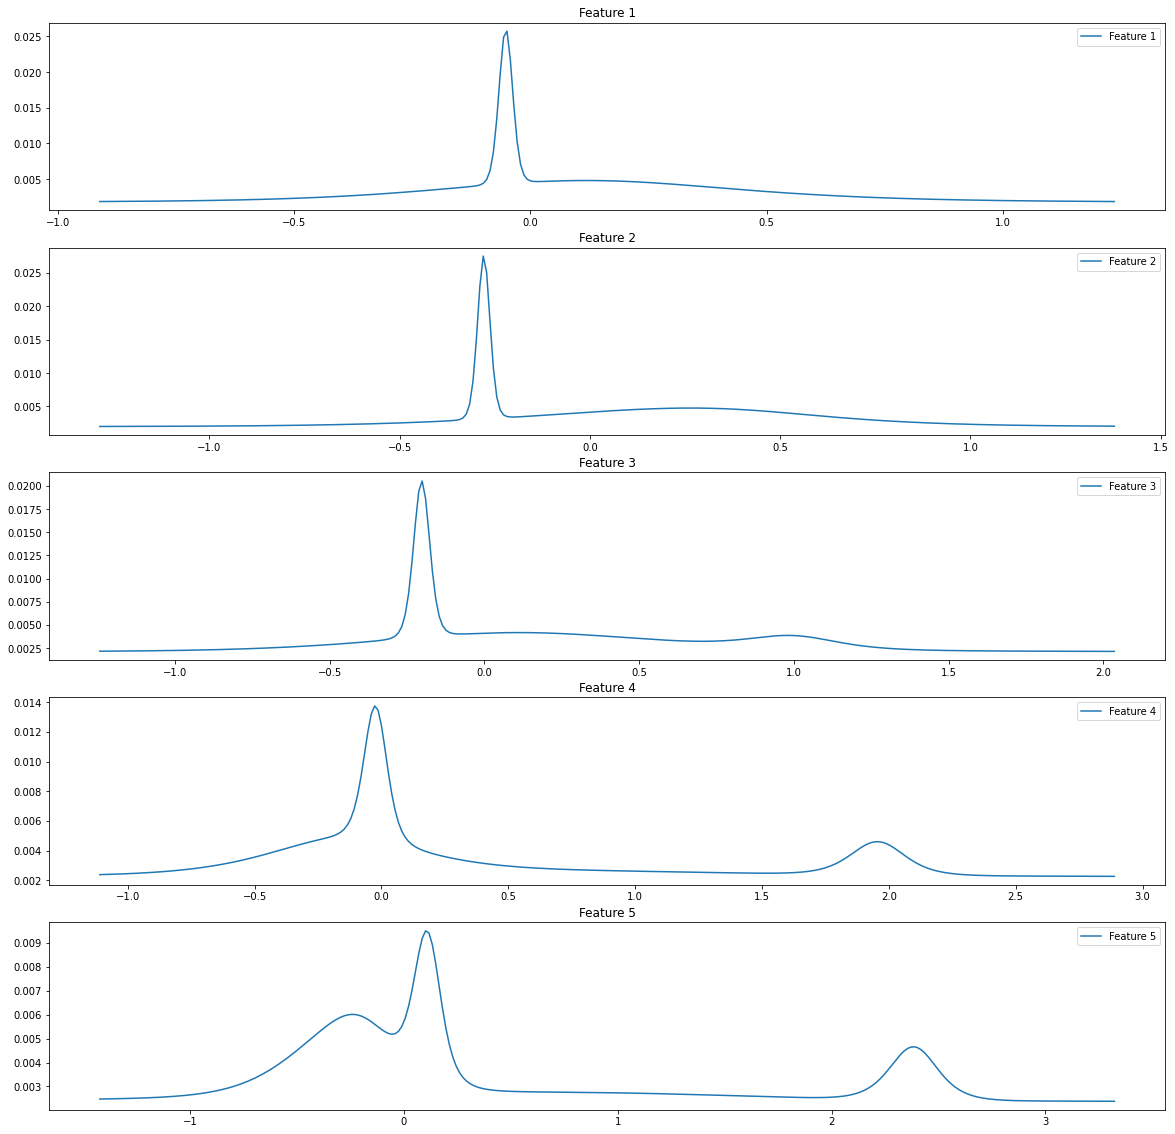

In [14]:
# best_model = Transformer(n_Layers=3, n_Embd=n_embedd, max_seq_length=10, dist_embed=).to(device)
plot_all_distributions = False
best_model.eval()
with torch.no_grad():
    mean, var, weight = best_model(dataset[0][0].unsqueeze(0).unsqueeze(-1), dataset[0][1].unsqueeze(0).unsqueeze(-1))
print(f'{mean = }')
print(f'{var = }')
print(f'{F.softmax(weight, dim=-1) = }')
tau = 100
n_cols = mean.shape[-1] + 1 if plot_all_distributions else 1
fig, ax = plt.subplots(mean.shape[-2], n_cols, figsize=(20,20))
# Iterate through each feature
for i, (m, v, w) in enumerate(zip(mean.squeeze(0), var.squeeze(0), weight.squeeze(0))):
    m, v, w = m.cpu(), v.cpu(), w.cpu()
    std = torch.sqrt(v)
    w_softmax = F.gumbel_softmax(w, dim=-1, hard=False, tau=tau)
    print(f'{w_softmax = }')

    # Prepare to sum the PDFs
    x_range = np.linspace(m.min() - 1 * std.max(), m.max() + 1 * std.max(), 300)
    combined_pdf = np.zeros_like(x_range)

    # Sum the weighted PDFs for each component
    for j in range(m.shape[0]):
        mu = m[j].cpu().numpy()
        sigma = std[j].cpu().numpy()
        alpha = w_softmax[j].cpu().numpy()

        # Weighted PDF of the current component
        y = F.softmax(torch.tensor(norm.pdf(x_range, mu, sigma))) * alpha
        

        # Plot the combined PDF for the current feature
        if plot_all_distributions:
            ax[i, j].plot(x_range, y, label=f"Feature {i+1}")
            ax[i, j].set_title(f"Feature {i+1}, Distribution {j+1}")
            ax[i, j].legend()

        # Add to the combined PDF
        combined_pdf += np.array(y)
    # Plot the combined PDF for the current feature
    if not plot_all_distributions:
        ax[i].plot(x_range, combined_pdf, label=f"Feature {i+1}")
        ax[i].set_title(f"Feature {i+1}")
        ax[i].legend()
    else:
        ax[i, j+1].plot(x_range, combined_pdf, label=f"Combined PDF for Feature {i+1}")
        ax[i, j+1].set_title(f"Feature 1 Combined")
        ax[i, j+1].legend()

print(weight)
plt.show()

In [39]:
epochs = 1
tau = 0.1
all_walks = []

for epoch in tqdm(range(epochs)):
    best_model.eval()

    total_loss = 0    
    # Process each target separately (assuming one input and different targets)
    with torch.no_grad():
        total_loss = 0
        for batch, target in dl:

            tgt = target[:,0].unsqueeze(1)

            for i in range(0,target.shape[1]-1):

                mean, var, weight = model(batch.unsqueeze(-1), tgt.unsqueeze(-1))  # Ignoring the last token for target

                gumbel_distribution = F.gumbel_softmax(weight[:, -1], tau=tau, hard=False)
                first_distribution = torch.distributions.Categorical(probs=gumbel_distribution)
                first_sample = first_distribution.sample()
                batch_indices = torch.arange(first_sample.size(0))
                var[:, -1] = var[:, -1]
                second_distribution = torch.distributions.Normal(mean[:, -1][batch_indices, first_sample], 
                                                    torch.sqrt(var[:, -1][batch_indices, first_sample]))
                second_sample = second_distribution.sample()
                predicted = torch.cat([tgt, second_sample.unsqueeze(1)], dim=1)

                tgt = predicted

            predicted = predicted.reshape(-1, predicted.shape[1])

            predicted_walks = np.array(predicted.cpu().numpy())+1

            cumprod_pred = np.cumprod(predicted_walks, axis=1)
            for i in range(cumprod_pred.shape[0]):
                all_walks.append(cumprod_pred[i])


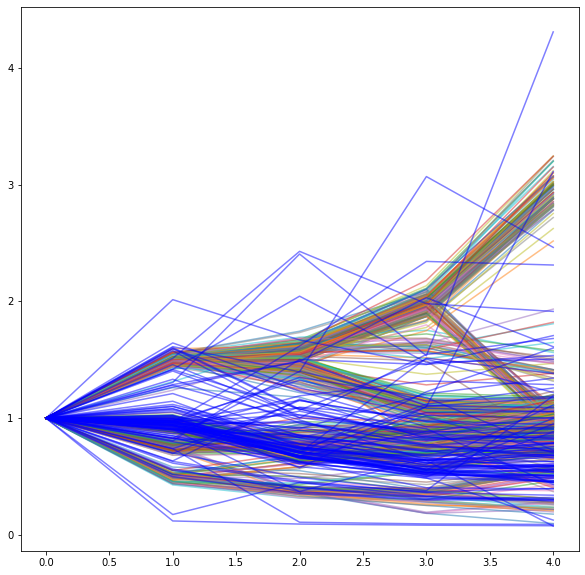

In [40]:
#plot all walks in matplot lib
plt.figure(figsize=(10,10))

for i in range(len(dataset)):
    sample = dataset[i][1][1:]
    sample = torch.cat([torch.zeros(1, device=device), sample])
    # cumprod = torch.cumprod(sample+1, dim=0).cpu().numpy()

    plt.plot(sample.cpu()+1, alpha=0.5)

# plt.figure(figsize=(10,10))
for walk in all_walks[:100]:
    plt.plot(walk, c='b', alpha=0.5)

plt.show()